In [2]:
import pandas as pd
import glob
import os
import matplotlib.pyplot as plt

In [3]:
for file in glob.glob("../data/*.csv"):
    df = pd.read_csv(file)
    print(os.path.basename(file), ":", df.columns.to_list())

Ad_table (extra).csv : ['Maker', ' Genmodel', ' Genmodel_ID', 'Adv_ID', 'Adv_year', 'Adv_month', 'Color', 'Reg_year', 'Bodytype', 'Runned_Miles', 'Engin_size', 'Gearbox', 'Fuel_type', 'Price', 'Engine_power', 'Annual_Tax', 'Wheelbase', 'Height', 'Width', 'Length', 'Average_mpg', 'Top_speed', 'Seat_num', 'Door_num']


C:\Users\jchmo\AppData\Local\Temp\ipykernel_56724\1745315391.py:2: DtypeWarning: Columns (13) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file)


Ad_table.csv : ['Maker', 'Genmodel', 'Genmodel_ID', 'Adv_ID', 'Adv_year', 'Adv_month', 'Color', 'Reg_year', 'Bodytype', 'Runned_Miles', 'Engin_size', 'Gearbox', 'Fuel_type', 'Price', 'Seat_num', 'Door_num']
Basic_table.csv : ['Automaker', 'Automaker_ID', 'Genmodel', 'Genmodel_ID']
Image_table.csv : ['Genmodel_ID', 'Image_ID', 'Image_name', 'Predicted_viewpoint', 'Quality_check']
Price_table.csv : ['Maker', 'Genmodel', 'Genmodel_ID', 'Year', 'Entry_price']
Sales_table.csv : ['Maker', 'Genmodel', 'Genmodel_ID', '2020', '2019', '2018', '2017', '2016', '2015', '2014', '2013', '2012', '2011', '2010', '2009', '2008', '2007', '2006', '2005', '2004', '2003', '2002', '2001']
Trim_table.csv : ['Genmodel_ID', 'Maker', 'Genmodel', 'Trim', 'Year', 'Price', 'Gas_emission', 'Fuel_type', 'Engine_size']


In [4]:
sales = pd.read_csv("../data/Sales_table.csv")

In [5]:
print(sales.head(10))

    Maker       Genmodel Genmodel_ID  2020  2019  2018  2017  2016  2015  \
0  ABARTH     ABARTH 124         2_1     0    19    27    60     0     0   
1  ABARTH     ABARTH 500         2_2     0     0     1     2    66   717   
2  ABARTH     ABARTH 595         2_4  2144  2866  3907  3295  3132  1612   
3  ABARTH     ABARTH 695         2_6    45    65   270   114    29    10   
4  ABARTH   ABARTH PUNTO         2_9     0     0     0     0     0     0   
5  ABARTH  ABARTH SPIDER         2_1     0   223   777   409   176     0   
6   ACURA       ACURA TL       100_1     0     0     0     0     0     0   
7   AIXAM      AIXAM 500         3_3     0     0     0     0     0     0   
8   AIXAM     AIXAM A751         3_4     0     0     0     0     0     0   
9   AIXAM    AIXAM COUPE         3_5     0     0     0     0     3     5   

   2014  ...  2010  2009  2008  2007  2006  2005  2004  2003  2002  2001  
0     0  ...     0     0     0     0     0     0     0     0     0     0  
1   762  ... 

In [6]:
print(sales.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 773 entries, 0 to 772
Data columns (total 23 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Maker        773 non-null    object
 1   Genmodel     773 non-null    object
 2   Genmodel_ID  773 non-null    object
 3   2020         773 non-null    int64 
 4   2019         773 non-null    int64 
 5   2018         773 non-null    int64 
 6   2017         773 non-null    int64 
 7   2016         773 non-null    int64 
 8   2015         773 non-null    int64 
 9   2014         773 non-null    int64 
 10  2013         773 non-null    int64 
 11  2012         773 non-null    int64 
 12  2011         773 non-null    int64 
 13  2010         773 non-null    int64 
 14  2009         773 non-null    int64 
 15  2008         773 non-null    int64 
 16  2007         773 non-null    int64 
 17  2006         773 non-null    int64 
 18  2005         773 non-null    int64 
 19  2004         773 non-null    

In [7]:
sales.shape

(773, 23)

In [8]:
print(sales.isna().sum())

Maker          0
Genmodel       0
Genmodel_ID    0
2020           0
2019           0
2018           0
2017           0
2016           0
2015           0
2014           0
2013           0
2012           0
2011           0
2010           0
2009           0
2008           0
2007           0
2006           0
2005           0
2004           0
2003           0
2002           0
2001           0
dtype: int64


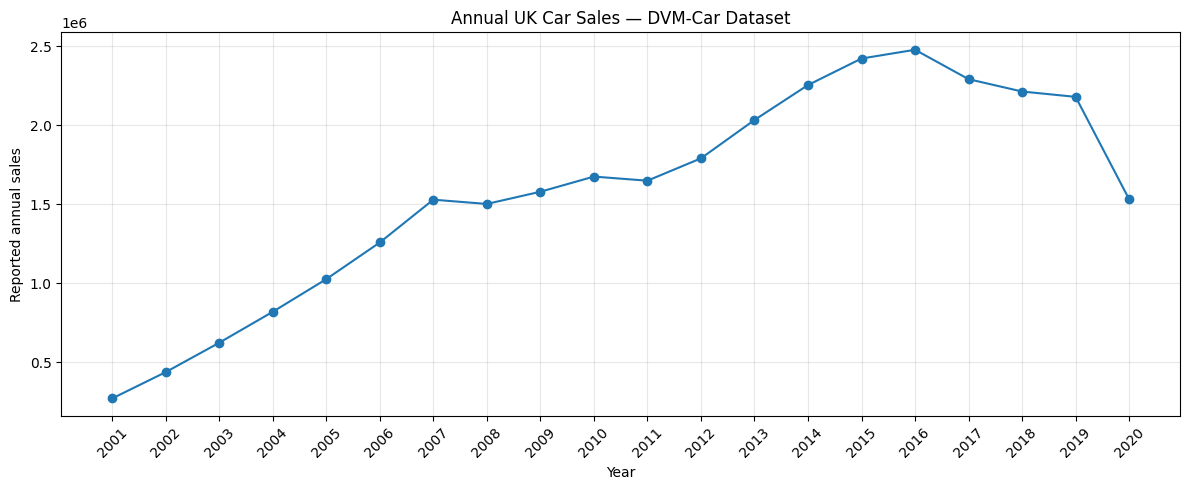

In [9]:
years = list(range(2001, 2021))

annual_sales = (
    sales.set_index("Genmodel_ID")[
        [str(year) for year in years]
    ]
    .sum(axis=0)
)

annual_sales.index = years

plt.figure(figsize=(12, 5))
plt.plot(annual_sales.index, annual_sales.values, marker="o")
plt.title("Annual UK Car Sales — DVM-Car Dataset")
plt.xlabel("Year")
plt.ylabel("Reported annual sales")
plt.xticks(years, rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
display(annual_sales.rename("Total_sales").to_frame())

,Total_sales
2001,269887
2002,436447
2003,622347
2004,818247
2005,1024944
2006,1256941
2007,1527848
2008,1500885
2009,1578106
2010,1674012


In [11]:
bmw = sales[
    sales["Maker"].str.strip().str.upper() == "BMW"
].copy()

print("number of BMW's: ", len(bmw))
display(bmw.head())

number of BMW's:  26


,Maker,Genmodel,Genmodel_ID,2020,2019,2018,2017,2016,2015,2014,...,2010,2009,2008,2007,2006,2005,2004,2003,2002,2001
84,BMW,BMW 1 SERIES,8_1,20764,23624,22628,27044,28879,30499,29722,...,27149,24467,21738,16022,14621,12155,3541,0,0,0
85,BMW,BMW 2 SERIES,8_2,9408,14842,18884,15426,19046,15197,4376,...,0,0,0,0,0,0,0,0,0,0
86,BMW,BMW 3 SERIES,8_5,19985,25262,25391,30716,32119,32799,34307,...,32119,28532,31514,38244,29965,21106,17464,17630,13416,9056
87,BMW,BMW 4 SERIES,8_7,4540,10539,15716,17039,18612,18745,13042,...,0,0,0,0,0,0,0,0,0,0
88,BMW,BMW 5 SERIES,8_9,8801,15789,19961,15263,15781,17442,16880,...,10856,9401,9940,11657,10233,7985,5534,4039,3628,2583


In [12]:
years = list(range(2001, 2021))
year_cols = [str(year) for year in years]

bmw_sales = (
    bmw[year_cols]
    .apply(pd.to_numeric, errors="coerce")
    .sum(axis=0)
)

bmw_sales.index = years
bmw_sales.index.name = "Year"
bmw_sales.name = "BMW sales"

display(bmw_sales.to_frame())

,BMW sales
Year,
2001,15263
2002,21856
2003,30390
2004,40699
2005,58097
2006,70394
2007,79648
2008,74725
2009,74348


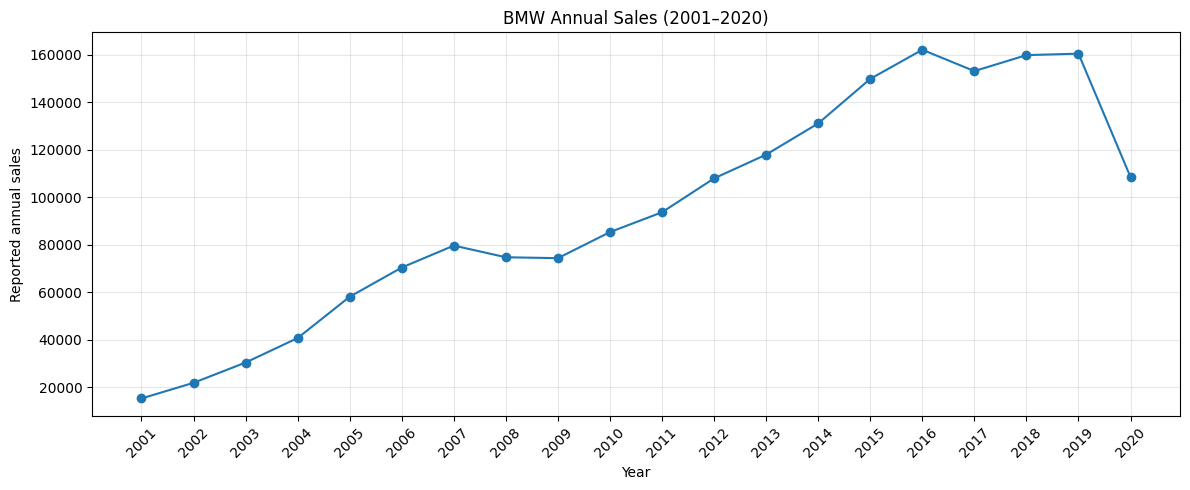

In [13]:
plt.figure(figsize=(12, 5))

plt.plot(
    bmw_sales.index,
    bmw_sales.values,
    marker="o"
)

plt.title("BMW Annual Sales (2001–2020)")
plt.xlabel("Year")
plt.ylabel("Reported annual sales")
plt.xticks(years, rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [14]:
# create time series
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.holtwinters import ExponentialSmoothing

y = bmw_sales.copy()
y.index = y.index.astype(int)
y = y.sort_index().astype(float)

train = y.loc[2001:2016]
test = y.loc[2017:2020]

print("train years:", train.index.min(), "-", train.index.max())
print("test years:", test.index.min(), "-", test.index.max())

display(pd.DataFrame({
    "Actual_sales": test
}))

train years: 2001 - 2016
test years: 2017 - 2020


,Actual_sales
Year,
2017,153127.0
2018,159848.0
2019,160464.0
2020,108462.0


In [15]:
import numpy as np

horizon = len(test)
# Model 1: Drift forecast
average_change = (
    (train.iloc[-1] - train.iloc[0])
    / (len(train) - 1)
)

drift_forecast = (
    train.iloc[-1]
    + average_change * np.arange(1, horizon + 1)
)

# Model 2: Naive forecast
naive_forecast = np.repeat(train.iloc[-1], horizon)

In [16]:
# Model 2: Holt's damped trend

train = train.copy()
train.index = pd.Index(train.index.astype(int), dtype="int64")
train = train.astype(float)

holt_model = ExponentialSmoothing(
    train.to_numpy(),
    trend="add",
    damped_trend=True,
    seasonal=None,
    initialization_method="estimated"
).fit(optimized=True)

horizon = 4
holt_forecast = holt_model.forecast(horizon)

print(holt_forecast)

# results
predictions = pd.DataFrame({
    "Actual": test,
    "Naive": np.repeat(train.iloc[-1], len(test)),
    "Drift": drift_forecast,
    "Holt_Damped": holt_forecast
}, index=test.index)

predictions.index.name = "Year"

display(predictions.round(0))

[173441.40400119 183598.65405051 192698.59695443 200851.2918721 ]


,Actual,Naive,Drift,Holt_Damped
Year,,,,
2017,153127.0,162104.0,171893.0,173441.0
2018,159848.0,162104.0,181683.0,183599.0
2019,160464.0,162104.0,191472.0,192699.0
2020,108462.0,162104.0,201262.0,200851.0


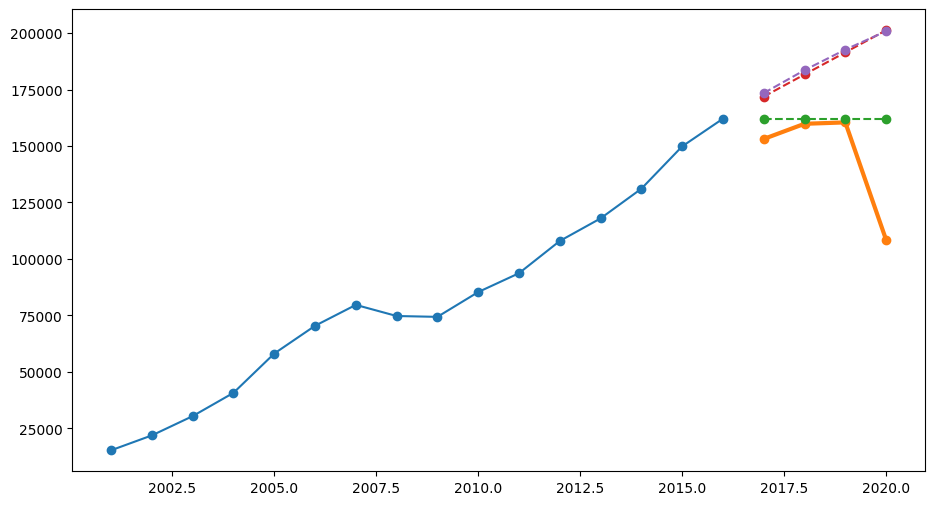

In [17]:
plt.figure(figsize=(11, 6))

plt.plot(
    train.index, train.values,
    label="Training data", marker="o"
)

plt.plot(
    test.index, test.values,
    label="Actual sales", marker="o", linewidth=3
)

for col in ["Naive", "Drift", "Holt_Damped"]:
    plt.plot(
        predictions.index,
        predictions[col],
        marker="o",
        linestyle="--",
        label=col
    )

In [18]:
results = []

for model in ["Naive", "Drift", "Holt_Damped"]:
    actual = predictions["Actual"]
    predicted = predictions[model]

    results.append({
        "Model": model,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "MAPE_pct": (
            np.abs((actual - predicted) / actual).mean() * 100
        )
    })

model_comparison = pd.DataFrame(results).sort_values("MAE")
display(model_comparison.round(2))

,Model,MAE,RMSE,MAPE_pct
0,Naive,16628.75,27229.72,14.44
1,Drift,41102.25,50995.61,32.70
2,Holt_Damped,42172.24,51360.54,33.35


In [19]:
eda = pd.DataFrame(index=bmw_sales.index)

eda["Sales"] = bmw_sales
eda["YoY_change"] = bmw_sales.pct_change() * 100
eda["Absolute_change"] = bmw_sales.diff()

display(eda.round(2))

,Sales,YoY_change,Absolute_change
Year,,,
2001,15263,NaN,NaN
2002,21856,43.20,6593.0
2003,30390,39.05,8534.0
2004,40699,33.92,10309.0
2005,58097,42.75,17398.0
2006,70394,21.17,12297.0
2007,79648,13.15,9254.0
2008,74725,-6.18,-4923.0
2009,74348,-0.50,-377.0


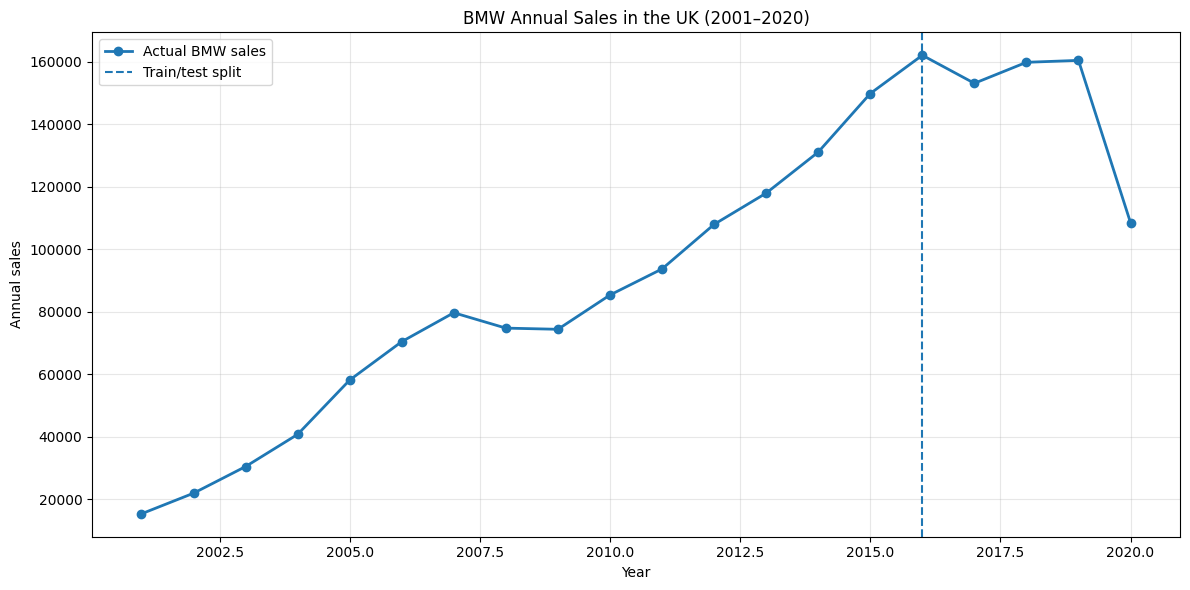

In [20]:
plt.figure(figsize=(12, 6))

plt.plot(
    bmw_sales.index,
    bmw_sales.values,
    marker="o",
    linewidth=2,
    label="Actual BMW sales"
)

plt.axvline(
    x=2016,
    linestyle="--",
    label="Train/test split"
)

plt.title("BMW Annual Sales in the UK (2001–2020)")
plt.xlabel("Year")
plt.ylabel("Annual sales")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [21]:
validation_years = range(2012, 2017)

model_specs = {
    "SES": {"trend": None, "damped_trend": False},
    "Holt": {"trend": "add", "damped_trend": False},
    "Holt_Damped": {"trend": "add", "damped_trend": True}
}

validation_results = []

for model_name, spec in model_specs.items():
    actual_values = []
    predicted_values = []

    for year in validation_years:
        history = y.loc[2001:year-1]

        model = ExponentialSmoothing(
            history.to_numpy(),
            trend=spec["trend"],
            damped_trend=spec["damped_trend"],
            seasonal=None,
            initialization_method="estimated"
        )

        fitted_model = model.fit(optimized=True)
        forecast = float(fitted_model.forecast(1)[0])

        actual_values.append(float(y.loc[year]))
        predicted_values.append(forecast)

    mae = mean_absolute_error(actual_values, predicted_values)
    rmse = np.sqrt(
        mean_squared_error(actual_values, predicted_values)
    )
    mape = np.mean(
        np.abs(
            (np.array(actual_values) - np.array(predicted_values))
            / np.array(actual_values)
        )
    ) * 100

    validation_results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE_pct": mape
    })

validation_comparison = (
    pd.DataFrame(validation_results)
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(validation_comparison.round(2))


,Model,MAE,RMSE,MAPE_pct
0,Holt,5161.02,5924.99,3.92
1,Holt_Damped,6190.38,6847.87,4.69
2,SES,13685.80,13988.77,10.36


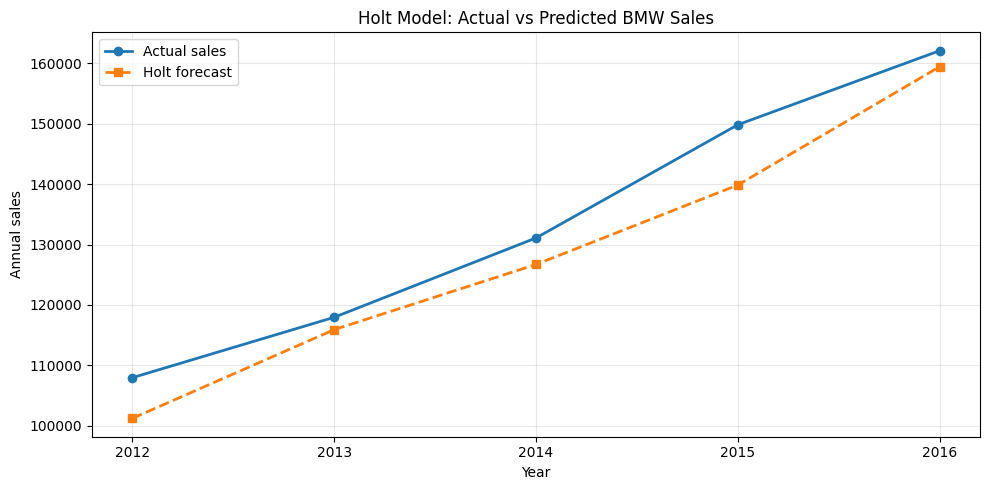

In [22]:
holt_actual = []
holt_predicted = []

for year in validation_years:
    history = y.loc[2001:year-1]

    model = ExponentialSmoothing(
        history.to_numpy(),
        trend="add",
        damped_trend=False,
        seasonal=None,
        initialization_method="estimated"
    ).fit(optimized=True)

    prediction = float(model.forecast(1)[0])

    holt_actual.append(float(y.loc[year]))
    holt_predicted.append(prediction)

plt.figure(figsize=(10, 5))

plt.plot(
    validation_years,
    holt_actual,
    marker="o",
    linewidth=2,
    label="Actual sales"
)

plt.plot(
    validation_years,
    holt_predicted,
    marker="s",
    linestyle="--",
    linewidth=2,
    label="Holt forecast"
)

plt.title("Holt Model: Actual vs Predicted BMW Sales")
plt.xlabel("Year")
plt.ylabel("Annual sales")
plt.xticks(validation_years)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig("../images/holt_validation.png", dpi=200, bbox_inches="tight")
plt.show()